## Лабораторная работа № 1. Часть 3
## Разведочный анализ собственного датасета на Apache Spark

Датасет — **«eCommerce behavior data from multi category store»** (Kaggle): журнал событий посетителей интернет-магазина за октябрь–ноябрь 2019 года. Совокупный объем — более 10 ГБ (свыше 100 млн строк), что соответствует требованию «не менее нескольких гигабайт».

Файлы датасета предварительно загружены в HDFS в каталог `/user/<user>/data/`.

**Отличие этой версии ноутбука:** весь код написан линейно, без вспомогательных функций и сложных конструкций; каждая строка снабжена комментарием.

### Описание признаков

Каждая строка датасета — одно событие (просмотр товара, добавление в корзину, удаление из корзины или покупка):

| Столбец | Тип признака | Расшифровка |
| ---- | ---- | ---- |
| `event_time` | временной | Момент совершения события |
| `event_type` | категориальный | Тип события: `view`, `cart`, `remove_from_cart`, `purchase` |
| `product_id` | идентификатор | Идентификатор товара |
| `category_id` | идентификатор | Идентификатор категории товара |
| `category_code` | категориальный | Код категории (`electronics.smartphone` и т.п.) |
| `brand` | категориальный | Бренд товара |
| `price` | количественный | Цена товара |
| `user_id` | идентификатор | Идентификатор пользователя |
| `user_session` | идентификатор | Идентификатор пользовательской сессии |

Подключим библиотеки.

In [13]:
# Модуль для работы с окружением (здесь — получение имени пользователя)
import os

# Классы PySpark: сессия и датафрейм
from pyspark.sql import SparkSession
# Объект конфигурации Spark-приложения
from pyspark import SparkConf

# Часто используемые функции над столбцами датафрейма:
# col — ссылка на столбец; to_timestamp / to_date / hour / dayofweek — работа с датой и временем;
# regexp_replace — замена по регулярному выражению; split / element_at — разбор строк;
# coalesce — выбор первого не-NULL значения
from pyspark.sql.functions import col, to_timestamp, to_date, hour, dayofweek, \
    regexp_replace, split, element_at

# Pandas — таблици на драйвере (для небольших результатов и графиков)
import pandas as pd
# Seaborn и Matplotlib — построение графиков
import seaborn as sns
import matplotlib.pyplot as plt

### Запуск Spark-сессии

Зададим конфигурацию: каждый параметр — отдельная строка с комментарием.

In [14]:
# Имя пользователя из переменной окружения (совпадает с именем каталога в HDFS)
user_name = os.getenv("USER")

# Создаем пустой объект конфигурации
conf = SparkConf()
# Имя приложения — под ним оно видно в веб-интерфейсе YARN
conf.setAppName("lab1 EDA simple")
# Запуск на кластере через менеджер ресурсов YARN
conf.setMaster("yarn")
# Режим client: драйвер выполняется на нашей машине (в сессии VS Code)
conf.set("spark.submit.deployMode", "client")
# Память одного исполнителя (executor)
conf.set("spark.executor.memory", "12g")
# Число ядер процессора одного исполнителя
conf.set("spark.executor.cores", "8")
# Число исполнителей в приложении
conf.set("spark.executor.instances", "2")
# Память драйвера
conf.set("spark.driver.memory", "4g")
# Число ядер драйвера
conf.set("spark.driver.cores", "2")
# Подключаем библиотеку Apache Iceberg (работа с таблицами поверх HDFS)
conf.set("spark.jars.packages", "org.apache.iceberg:iceberg-spark-runtime-3.5_2.12:1.6.0")
# Расширения Spark SQL с командами Iceberg (CREATE TABLE и т.п.)
conf.set("spark.sql.extensions", "org.apache.iceberg.spark.extensions.IcebergSparkSessionExtensions")
# Каталог spark_catalog будет обслуживаться классом Iceberg
conf.set("spark.sql.catalog.spark_catalog", "org.apache.iceberg.spark.SparkCatalog")
# Тип каталога — hadoop (метаданные хранятся в HDFS)
conf.set("spark.sql.catalog.spark_catalog.type", "hadoop")
# Путь к «складу» таблиц Iceberg в HDFS
conf.set("spark.sql.catalog.spark_catalog.warehouse", f"hdfs:///user/{user_name}/warehouse")
# Реализация файлового ввода-вывода каталога
conf.set("spark.sql.catalog.spark_catalog.io-impl", "org.apache.iceberg.hadoop.HadoopFileIO")

In [15]:
# Создаем Spark-сессию с заданной конфигурацией (или подключаемся к существующей)
spark = SparkSession.builder.config(conf=conf).getOrCreate()
spark

26/10/26 20:29:43 WARN SparkSession: Using an existing Spark session; only runtime SQL configurations will take effect.


### Загрузка данных

Прочитаем CSV-файлы из HDFS. Все столбцы сначала читаются как строки, типы зададим явно на следующем шаге.

In [16]:
# Путь к файлам датасета в HDFS; маска *.csv захватывает все файлы (Oct и Nov)
data_path = f"hdfs:///user/{user_name}/data/*.csv"

# Читаем CSV-файлы в датафрейм Spark
df = (
    spark.read
    .format("csv")                 # формат источника данных — CSV
    .option("header", "true")      # первая строка файла — заголовок с именами столбцов
    .load(data_path)               # загрузка данных по указанному пути
)

In [17]:
# Показываем первые 5 строк датафрейма (truncate=False — не обрезать длинные значения)
df.show(5, truncate=False)

+-----------------------+----------+----------+-------------------+-------------------------+------+------+---------+------------------------------------+
|event_time             |event_type|product_id|category_id        |category_code            |brand |price |user_id  |user_session                        |
+-----------------------+----------+----------+-------------------+-------------------------+------+------+---------+------------------------------------+
|2019-11-01 00:00:00 UTC|view      |1003461   |2053013555631882655|electronics.smartphone   |xiaomi|489.07|520088904|4d3b30da-a5e4-49df-b1a8-ba5943f1dd33|
|2019-11-01 00:00:00 UTC|view      |5000088   |2053013566100866035|appliances.sewing_machine|janome|293.65|530496790|8e5f4f83-366c-4f70-860e-ca7417414283|
|2019-11-01 00:00:01 UTC|view      |17302664  |2053013553853497655|NULL                     |creed |28.31 |561587266|755422e7-9040-477b-9bd2-6a6e8fd97387|
|2019-11-01 00:00:01 UTC|view      |3601530   |2053013563810775923|app

In [18]:
# Печатаем схему датафрейма: имена и типы столбцов
df.printSchema()

root
 |-- event_time: string (nullable = true)
 |-- event_type: string (nullable = true)
 |-- product_id: string (nullable = true)
 |-- category_id: string (nullable = true)
 |-- category_code: string (nullable = true)
 |-- brand: string (nullable = true)
 |-- price: string (nullable = true)
 |-- user_id: string (nullable = true)
 |-- user_session: string (nullable = true)



In [19]:
# Считаем число строк в датафрейме (действие — запускает вычисления на кластере)
df.count()

109950743

### Приведение типов и производные признаки

Запись времени имеет вид `2019-10-01 00:00:00 UTC`. Уберем суффикс `UTC`, приведем столбцы к нужным типам и добавим производные признаки: дату события, час и день недели (пригодятся для анализа динамики и корреляций).

In [20]:
# В event_time заменяем окончание " UTC" на пустую строку и разбираем дату-время
df = df.withColumn("event_time", to_timestamp(regexp_replace("event_time", " UTC$", ""), "yyyy-MM-dd HH:mm:ss"))

# Идентификаторы приводим к целочисленному типу long
df = df.withColumn("product_id", col("product_id").cast("long"))
df = df.withColumn("category_id", col("category_id").cast("long"))
df = df.withColumn("user_id", col("user_id").cast("long"))

# Цену приводим к дробному типу double
df = df.withColumn("price", col("price").cast("double"))

# Производный признак: только дата события (без времени)
df = df.withColumn("event_date", to_date("event_time"))
# Производный признак: час суток (0–23)
df = df.withColumn("hour", hour("event_time"))
# Производный признак: номер дня недели (1 — воскресенье, 7 — суббота)
df = df.withColumn("day_of_week", dayofweek("event_time"))

# Проверяем новые типы столбцов
df.printSchema()

root
 |-- event_time: timestamp (nullable = true)
 |-- event_type: string (nullable = true)
 |-- product_id: long (nullable = true)
 |-- category_id: long (nullable = true)
 |-- category_code: string (nullable = true)
 |-- brand: string (nullable = true)
 |-- price: double (nullable = true)
 |-- user_id: long (nullable = true)
 |-- user_session: string (nullable = true)
 |-- event_date: date (nullable = true)
 |-- hour: integer (nullable = true)
 |-- day_of_week: integer (nullable = true)



### Сохранение типизированных данных в Apache Iceberg

Каждую таблицу называем по фамилии студента. Создадим базу данных и сохраним «сырую» типизированную таблицу.

In [21]:
# Фамилия студента латиницей (используется в именах базы и таблиц)
student_surname = "korolev"  # TODO: замените на свою фамилию

# Имя базы данных
database_name = f"{student_surname}_database"
# Имя таблицы с типизированными «сырыми» данными
table_raw_name = f"{student_surname}_lab1_events_raw"
# Имя итоговой таблицы с очищенными данными
table_processed_name = f"{student_surname}_lab1_events_processed"

In [22]:
# SQL-команда: создать базу данных, если ее еще нет
create_database_sql = f"CREATE DATABASE IF NOT EXISTS spark_catalog.{database_name}"
# Выполняем команду
spark.sql(create_database_sql)

# Делаем созданную базу данных текущей
spark.catalog.setCurrentDatabase(database_name)

In [23]:
# Записываем датафрейм в новую таблицу Iceberg (операция может быть долгой).
# Если таблица уже существует с прошлого запуска, сначала удалите ее:
# spark.sql(f"DROP TABLE {table_raw_name}")
df.writeTo(table_raw_name).using("iceberg").create()

In [24]:
# Читаем сохраненную таблицу обратно и дальше работаем с данными из Iceberg
df = spark.table(table_raw_name)
df.show(5, truncate=False)

+-------------------+----------+----------+-------------------+----------------------+-------+-------+---------+------------------------------------+----------+----+-----------+
|event_time         |event_type|product_id|category_id        |category_code         |brand  |price  |user_id  |user_session                        |event_date|hour|day_of_week|
+-------------------+----------+----------+-------------------+----------------------+-------+-------+---------+------------------------------------+----------+----+-----------+
|2019-11-07 06:04:42|view      |12719963  |2053013553559896355|NULL                  |kapsen |57.92  |564342718|10500e14-e65c-45fc-8f8e-8ba62033d866|2019-11-07|6   |5          |
|2019-11-07 06:04:43|view      |1005135   |2053013555631882655|electronics.smartphone|apple  |1645.93|519858837|a9e604a2-a199-476b-b59a-8adbc3c48b38|2019-11-07|6   |5          |
|2019-11-07 06:04:43|view      |1004994   |2053013555631882655|electronics.smartphone|oneplus|540.3  |56843728

## Разведочный анализ данных

### Пропущенные значения

Пройдем по всем столбцам и посчитаем число и долю строк с NULL.

In [25]:
# Общее число строк (запомним, чтобы считать доли)
total_count = df.count()

# Цикл по всем столбцам датафрейма
for column_name in df.columns:
    # Число строк, в которых столбец равен NULL (фильтр + count)
    null_count = df.filter(col(column_name).isNull()).count()
    # Печатаем: имя столбца, число пропусков, доля в процентах
    print(f"{column_name}: {null_count} ({100 * null_count / total_count:.2f}%)")

event_time: 0 (0.00%)
event_type: 0 (0.00%)
product_id: 0 (0.00%)
category_id: 0 (0.00%)


category_code: 35413780 (32.21%)


brand: 15331243 (13.94%)
price: 0 (0.00%)
user_id: 0 (0.00%)


user_session: 12 (0.00%)
event_date: 0 (0.00%)
hour: 0 (0.00%)
day_of_week: 0 (0.00%)


Пропуски есть в трех столбцах: `category_code` (~треть строк), `brand` (~15%) и `user_session` (доли процента).

Пропуски в **категориальных** признаках заменим явной категорией `unknown` (такой прием сохраняет строки и помечает отсутствие данных). Строки без `user_session` удалим — их мало, а идентификатор сессии нужен для корректной интерпретации событий.

In [26]:
# Заменяем NULL на строку "unknown" в двух категориальных столбцах
df = df.fillna({"category_code": "unknown", "brand": "unknown"})

# Оставляем только строки, где идентификатор сессии не NULL
df = df.filter(col("user_session").isNotNull())

# Число строк после обработки пропусков
df.count()

109950731

In [27]:
# Создаем столбец category_l1 — верхний уровень категории:
# split делит код категории по точке, element_at берет первый элемент
df = df.withColumn("category_l1", element_at(split(col("category_code"), r"\."), 1))

### Дубликаты

Ключом события считаем набор столбцов `event_time`, `event_type`, `product_id`, `user_id`, `user_session`: совпадение всех значений означает, что одно событие записано дважды.

In [28]:
# Столбцы, вместе однозначно определяющие событие
key_columns = ["event_time", "event_type", "product_id", "user_id", "user_session"]

# Число строк до удаления дубликатов
print(f"Строк до удаления дубликатов: {df.count()}")

# Удаляем строки-повторы по указанному набору столбцов
df = df.dropDuplicates(key_columns)

# Число строк после удаления дубликатов
print(f"Строк после удаления дубликатов: {df.count()}")

Строк до удаления дубликатов: 109950731


Строк после удаления дубликатов: 109819981


### Числовые статистики и выбросы признака `price`

Выведем сводные статистики цены: количество, среднее, стандартное отклонение, минимум, квартили, максимум.

In [29]:
# Сводные статистики по столбцу price
df.select("price").summary().show()

+-------+------------------+
|summary|             price|
+-------+------------------+
|  count|         109819981|
|   mean|291.64426751693776|
| stddev|356.72894178127035|
|    min|               0.0|
|    25%|             67.96|
|    50%|            164.92|
|    75%|            360.11|
|    max|           2574.07|
+-------+------------------+



Среднее заметно больше медианы, а максимум на порядки выше типичных значений — распределение цены имеет «тяжелый» правый хвост. Выбросы двух типов:

1. **Неположительные цены** — явная ошибка данных (цена не может быть ≤ 0);
2. **Экстремально большие цены** — редкие, но законные дорогие товары.

Правило «полтора межквартильных размаха» (IQR) здесь отрезало бы слишком много корректных дорогих товаров, поэтому сверху ограничим признак **99-м перцентилем**.

In [30]:
# Число событий с неположительной ценой (ошибочные данные)
print(f"Событий с ценой <= 0: {df.filter(col('price') <= 0).count()}")

# 99-й перцентиль цены: 99% товаров дешевле этого значения
q99 = df.approxQuantile("price", [0.99], 0.001)[0]
print(f"99-й перцентиль цены: {q99:.2f}")

# Число строк, которые будут удалены как выбросы
print(f"Удаляется строк: {df.filter((col('price') <= 0) | (col('price') > q99)).count()}")

# Оставляем строки с ценой строго больше 0 и не больше q99
df = df.filter((col("price") > 0) & (col("price") <= q99))

# Число строк после удаления выбросов
df.count()

Событий с ценой <= 0: 256657


99-й перцентиль цены: 1673.14


Удаляется строк: 1386742


108433239

### Визуализации распределений

Все графики строятся так: сначала на кластере агрегируем данные до маленькой таблицы (`groupBy` + `count`), затем `toPandas()` выгружает ее на драйвер, и график рисует Seaborn.

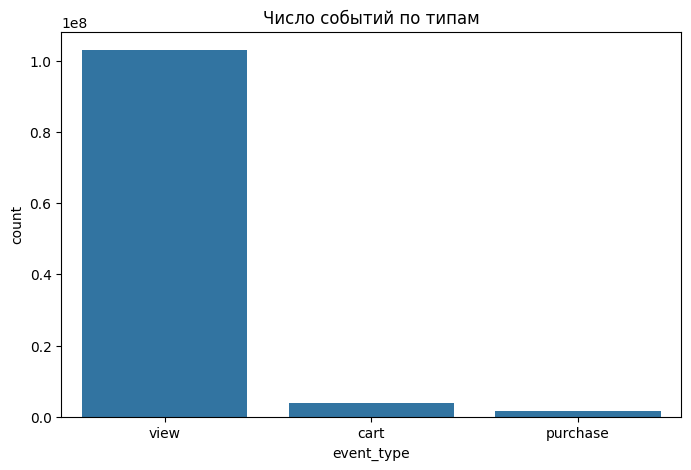

In [31]:
# Число событий каждого типа (маленькая таблица после агрегации — можно в pandas)
event_types = df.groupBy("event_type").count().orderBy("count", ascending=False).toPandas()

# Размер фигуры в дюймах
plt.figure(figsize=(8, 5))
# Столбчатая диаграмма: типы событий по горизонтали
sns.barplot(data=event_types, x="event_type", y="count")
# Заголовок графика
plt.title("Число событий по типам")
plt.show()

Подавляющая часть событий — просмотры (`view`): на каждую покупку приходится много просмотров, что типично для интернет-магазинов.

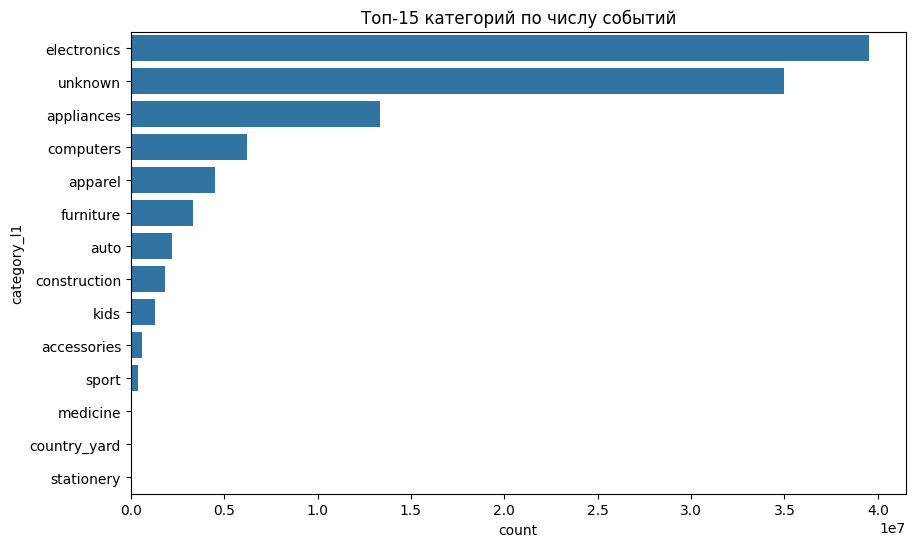

In [32]:
# Топ-15 категорий верхнего уровня по числу событий
top_categories = (
    df.groupBy("category_l1")            # группируем по категории
    .count()                             # считаем события в каждой
    .orderBy("count", ascending=False)   # сортируем по убыванию
    .limit(15)                           # берем первые 15
    .toPandas()                          # выгружаем на драйвер
)

plt.figure(figsize=(10, 6))
# Категории по вертикали, числа событий — по горизонтали
sns.barplot(data=top_categories, y="category_l1", x="count")
plt.title("Топ-15 категорий по числу событий")
plt.show()

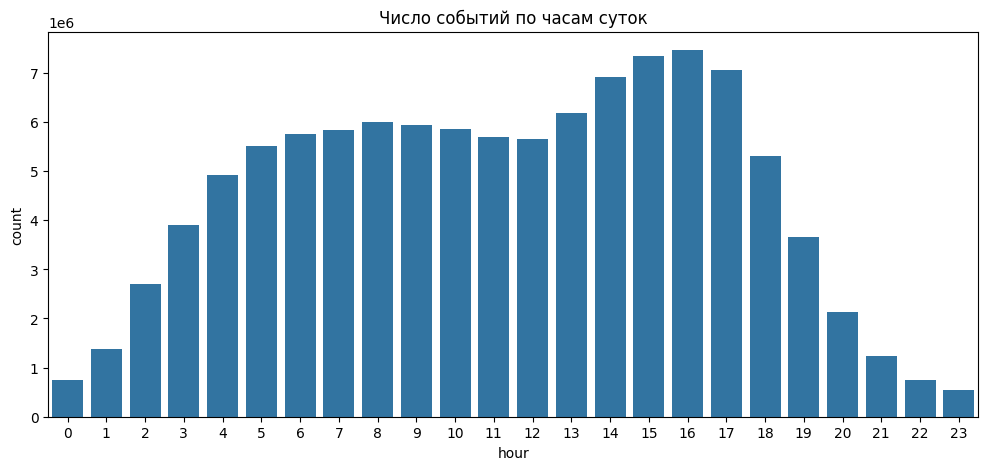

In [33]:
# Число событий по часам суток, отсортировано по часу
events_by_hour = df.groupBy("hour").count().orderBy("hour").toPandas()

plt.figure(figsize=(12, 5))
sns.barplot(data=events_by_hour, x="hour", y="count")
plt.title("Число событий по часам суток")
plt.show()

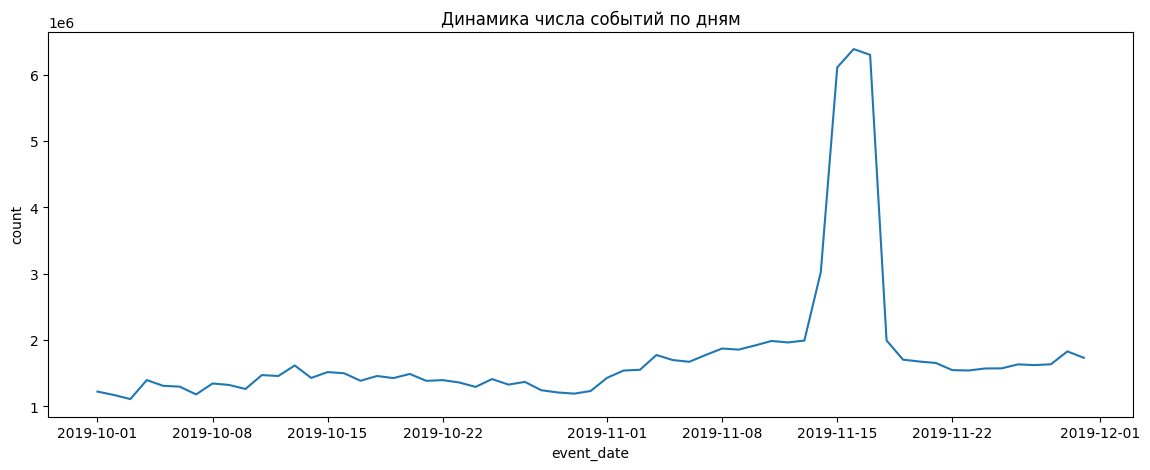

In [34]:
# Динамика числа событий по датам
events_by_date = df.groupBy("event_date").count().orderBy("event_date").toPandas()

plt.figure(figsize=(14, 5))
# Линейный график подходит для временного ряда
sns.lineplot(data=events_by_date, x="event_date", y="count")
plt.title("Динамика числа событий по дням")
plt.show()

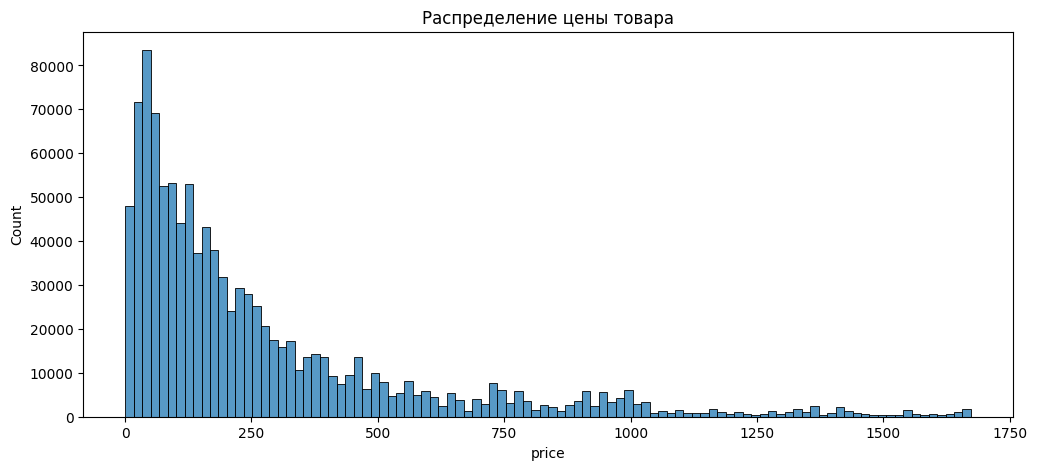

In [35]:
# Для гистограммы цены берем случайную 1%-ю выборку:
# все ~100 млн строк не поместятся в память драйвера, а выборка дает ту же картину
prices = df.select("price").sample(withReplacement=False, fraction=0.01).toPandas()

plt.figure(figsize=(12, 5))
# Гистограмма со 100 столбиками
sns.histplot(data=prices, x="price", bins=100)
plt.title("Распределение цены товара")
plt.show()

### Производные количественные признаки и корреляции

«Естественный» количественный признак в данных один — `price`. Добавим к нему `hour`, `day_of_week` (введены выше) и два признака, посчитанных агрегацией:

* `user_activity` — общее число событий пользователя;
* `product_popularity` — общее число событий, связанных с товаром.

In [36]:
# Активность пользователя: группируем события по user_id и считаем их число
user_activity = (
    df.groupBy("user_id")
    .count()                                  # число событий пользователя
    .withColumnRenamed("count", "user_activity")  # переименовываем столбец count
)

# Присоединяем активность к событиям по ключу user_id
df = df.join(user_activity, on="user_id", how="left")

# Популярность товара: число событий с товаром по product_id
product_popularity = (
    df.groupBy("product_id")
    .count()
    .withColumnRenamed("count", "product_popularity")
)

# Присоединяем популярность к событиям по ключу product_id
df = df.join(product_popularity, on="product_id", how="left")

# Кэшируем датафрейм в памяти: ниже он используется несколько раз
df = df.cache()

In [37]:
# Список количественных признаков для корреляционного анализа
numeric_columns = ["price", "hour", "day_of_week", "user_activity", "product_popularity"]

# Сюда соберем строки будущей матрицы
corr_rows = []

# Внешний цикл — первый признак пары
for col1 in numeric_columns:
    # Строка значений для признака col1
    row = []
    # Внутренний цикл — второй признак пары
    for col2 in numeric_columns:
        # Коэффициент корреляции Пирсона между col1 и col2
        value = df.corr(col1, col2)
        # Округляем до трех знаков и добавляем в строку
        row.append(round(value, 3))
    corr_rows.append(row)

# Собираем матрицу в таблицу pandas (подписи строк и столбцов — названия признаков)
corr_matrix = pd.DataFrame(corr_rows, index=numeric_columns, columns=numeric_columns)
corr_matrix

,price,hour,day_of_week,user_activity,product_popularity
price,1.000,0.011,0.007,-0.023,0.166
hour,0.011,1.000,0.008,0.010,-0.020
day_of_week,0.007,0.008,1.000,0.005,0.003
user_activity,-0.023,0.010,0.005,1.000,-0.049
product_popularity,0.166,-0.020,0.003,-0.049,1.000


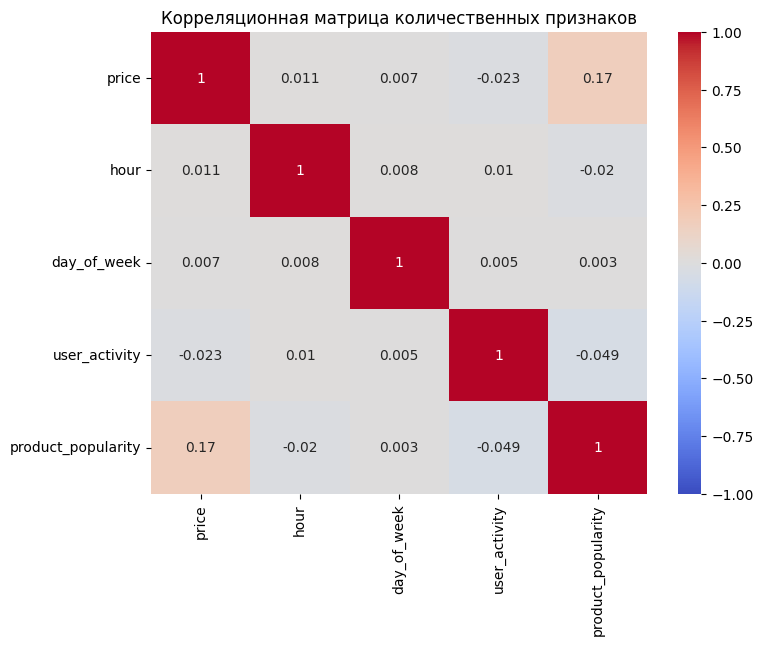

In [38]:
plt.figure(figsize=(8, 6))
# Тепловая карта матрицы корреляций с числами в ячейках
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Корреляционная матрица количественных признаков")
plt.show()

Линейные связи между количественными признаками слабые. Это ожидаемо для событийных данных: цена не зависит от времени суток, а активность и популярность определяются категориальными характеристиками (категория, бренд). Зависимости такого рода видны на диаграммах выше (распределения по категориям, часам, дням), полученных группировками.

### Сохранение результата и выводы

In [39]:
# Сохраняем очищенный датафрейм в итоговую таблицу Iceberg.
# Если таблица существует с прошлого запуска: spark.sql(f"DROP TABLE {table_processed_name}")
df.writeTo(table_processed_name).using("iceberg").create()

# Список таблиц текущей базы данных — проверка, что обе таблицы на месте
for table in spark.catalog.listTables():
    print(table.name)

korolev_lab1_events_processed
korolev_lab1_events_raw


**Выводы.** В ходе разведочного анализа датасета (более 10 ГБ, свыше 100 млн событий) на Apache Spark:

* определены типы всех признаков и выполнено приведение типов из CSV;
* выявлены и обработаны пропуски: `category_code` и `brand` заполнены категорией `unknown`, строки без `user_session` удалены;
* найдены и удалены дубликаты событий по ключу из пяти столбцов;
* выявлены и удалены выбросы цены: неположительные значения и значения выше 99-го перцентиля;
* рассчитаны сводные статистики количественных признаков;
* построены распределения типов событий, категорий, цены и временная динамика;
* рассчитана корреляционная матрица: линейные связи количественных признаков слабые, что типично для событийных данных.

Очищенные данные сохранены в таблицу `Apache Iceberg` и пригодны для дальнейшей работы (например, построения моделей в лабораторной работе № 2).

In [40]:
# Останавливаем Spark-сессию, освобождая ресурсы кластера
spark.stop()